In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from gensim.models import Word2Vec, KeyedVectors
from gensim.models.fasttext import FastText
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [7]:
df = pd.read_csv(r"D:\Semester 5\NLP\modul-1\dataset_preprocessed.csv")
text_column = "processed_text"
df = df.dropna(subset=[text_column])

# Buat list of list untuk Word2Vec
sentences = [
    str(text).split()
    for text in df[text_column]
]

print(f"Jumlah kalimat: {len(sentences)}")
print(f"Contoh kalimat: {sentences[0][:10]}")

Jumlah kalimat: 9803
Contoh kalimat: ['bang', 'kumis', 'milik', 'karakter', 'salesman', 'yg', 'kuat', 'ciri', 'khas', 'ulang']


In [8]:
# Latih model Word2Vec
model_w2v = Word2Vec(
    sentences=sentences,
    vector_size=100,    # dimensi embedding
    window=5,           # ukuran konteks kiri-kanan
    min_count=2,        # abaikan kata yang muncul < 2 kali
    workers=4,          # jumlah thread
    epochs=10,          # iterasi training
    sg=1                # 1 = Skip-gram, 0 = CBOW
)

print("Model Word2Vec berhasil dilatih.")
print(f"Ukuran vocabulary: {len(model_w2v.wv)}")

Model Word2Vec berhasil dilatih.
Ukuran vocabulary: 5140


In [ ]:
from pathlib import Path
from gensim.models import Word2Vec

model_path = Path(r"D:\Semester 5\NLP\Modul - 2\word2vec_model.bin")

if "model_w2v" in globals():
    model_w2v.save(str(model_path))
    print(f"Model Word2Vec berhasil disimpan: {model_path}")
elif model_path.exists():
    model_w2v = Word2Vec.load(str(model_path))
    print(f"Model Word2Vec berhasil dimuat: {model_path}")
else:
    raise RuntimeError(
        "Model belum dilatih dan file model tidak ditemukan. "
        "Jalankan sel pelatihan Word2Vec terlebih dahulu."
    )

In [10]:
# Contoh kata dari dataset
sample_word = "bagus"

if sample_word in model_w2v.wv:
    vector = model_w2v.wv[sample_word]
    print(f"Vektor '{sample_word}':")
    print(f"  Dimensi : {vector.shape}")
    print(f"  Nilai   : {vector[:10]}...")  # tampilkan 10 dimensi pertama
else:
    print(f"Kata '{sample_word}' tidak ada dalam vocabulary.")

Vektor 'bagus':
  Dimensi : (100,)
  Nilai   : [-0.299369    0.34197658 -0.20251939  0.18752448 -0.08664733 -0.4152085
 -0.0903768   0.45906734 -0.23232152 -0.2895983 ]...


In [11]:
def find_similar_words(word, model, top_n=10):
    if word not in model.wv:
        print(f"Kata '{word}' tidak ada dalam vocabulary.")
        return []
    similar = model.wv.most_similar(word, topn=top_n)
    return similar

# Contoh
test_words = ["bagus", "buruk", "hotel", "pelayanan"]

for word in test_words:
    print(f"\nKata yang mirip dengan '{word}':")
    similar = find_similar_words(word, model_w2v)
    for similar_word, score in similar:
        print(f"  {similar_word:<20} : {score:.4f}")


Kata yang mirip dengan 'bagus':
  jelek                : 0.8150
  niat                 : 0.8131
  benah                : 0.8044
  tata                 : 0.8011
  sana                 : 0.7910
  laksana              : 0.7906
  pelaksanaanya        : 0.7857
  sasar                : 0.7845
  ttp                  : 0.7840
  amburadul            : 0.7795

Kata yang mirip dengan 'buruk':
  terap                : 0.9135
  rencana              : 0.9093
  niat                 : 0.9018
  faktor               : 0.8993
  nasional             : 0.8984
  point                : 0.8900
  amburadul            : 0.8892
  cenderung            : 0.8831
  kuantitas            : 0.8827
  skala                : 0.8820

Kata yang mirip dengan 'hotel':
  sawi                 : 0.9835
  cpt                  : 0.9821
  modern               : 0.9818
  makananan            : 0.9798
  bpom                 : 0.9773
  singkong             : 0.9772
  dicobain             : 0.9771
  ssya                 : 0.9769
  exp

In [12]:
def word_similarity(word1, word2, model):
    if word1 not in model.wv or word2 not in model.wv:
        return None
    return model.wv.similarity(word1, word2)

# Uji beberapa pasangan kata
pairs = [
    ("bagus", "baik"),
    ("bagus", "buruk"),
    ("hotel", "penginapan"),
    ("hotel", "mobil"),
]

print("Similarity antar kata:")
print("-" * 40)
for w1, w2 in pairs:
    sim = word_similarity(w1, w2, model_w2v)
    if sim is not None:
        print(f"  {w1} ↔ {w2:<20}: {sim:.4f}")

Similarity antar kata:
----------------------------------------
  bagus ↔ baik                : 0.7495
  bagus ↔ buruk               : 0.7636
  hotel ↔ mobil               : 0.9083


In [13]:
# Cari kata yang paling mendekati: positif - negatif + ...
try:
    result = model_w2v.wv.most_similar(
        positive=["bagus", "pelayanan"],
        negative=["buruk"],
        topn=5
    )
    print("Hasil operasi vektor:")
    for word, score in result:
        print(f"  {word:<20} : {score:.4f}")
except Exception as e:
    print(f"Error: {e}")
    print("Pastikan kata-kata tersebut ada dalam vocabulary.")

Error: "Key 'pelayanan' not present in vocabulary"
Pastikan kata-kata tersebut ada dalam vocabulary.


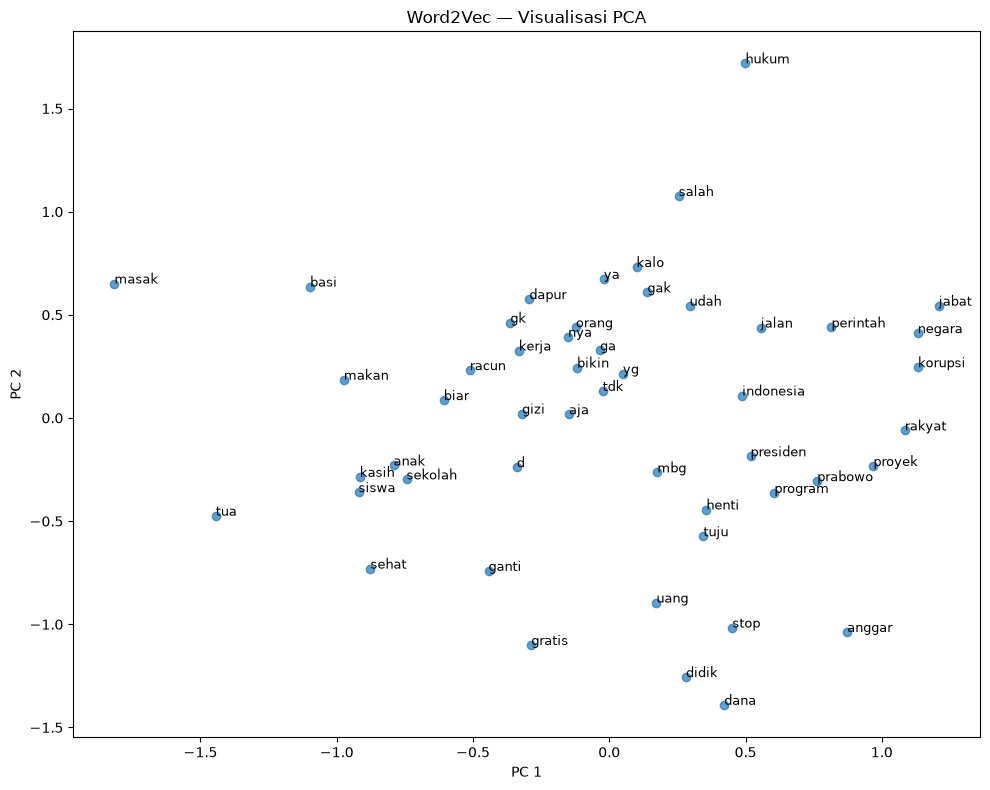

In [14]:
def visualize_embeddings_pca(words, model, title="Word Embedding PCA"):
    # Filter kata yang ada dalam vocabulary
    valid_words = [w for w in words if w in model.wv]
    if not valid_words:
        print("Tidak ada kata yang tersedia dalam vocabulary.")
        return

    vectors = np.array([model.wv[w] for w in valid_words])

    # Reduksi ke 2D dengan PCA
    pca = PCA(n_components=2)
    vectors_2d = pca.fit_transform(vectors)

    plt.figure(figsize=(10, 8))
    plt.scatter(vectors_2d[:, 0], vectors_2d[:, 1], alpha=0.7)
    for i, word in enumerate(valid_words):
        plt.annotate(
            word,
            xy=(vectors_2d[i, 0], vectors_2d[i, 1]),
            fontsize=9
        )
    plt.title(title)
    plt.xlabel("PC 1")
    plt.ylabel("PC 2")
    plt.tight_layout()
    plt.show()

# Ambil top 50 kata paling sering
top_words = [word for word, _ in model_w2v.wv.key_to_index.items()][:50]
visualize_embeddings_pca(top_words, model_w2v, "Word2Vec — Visualisasi PCA")

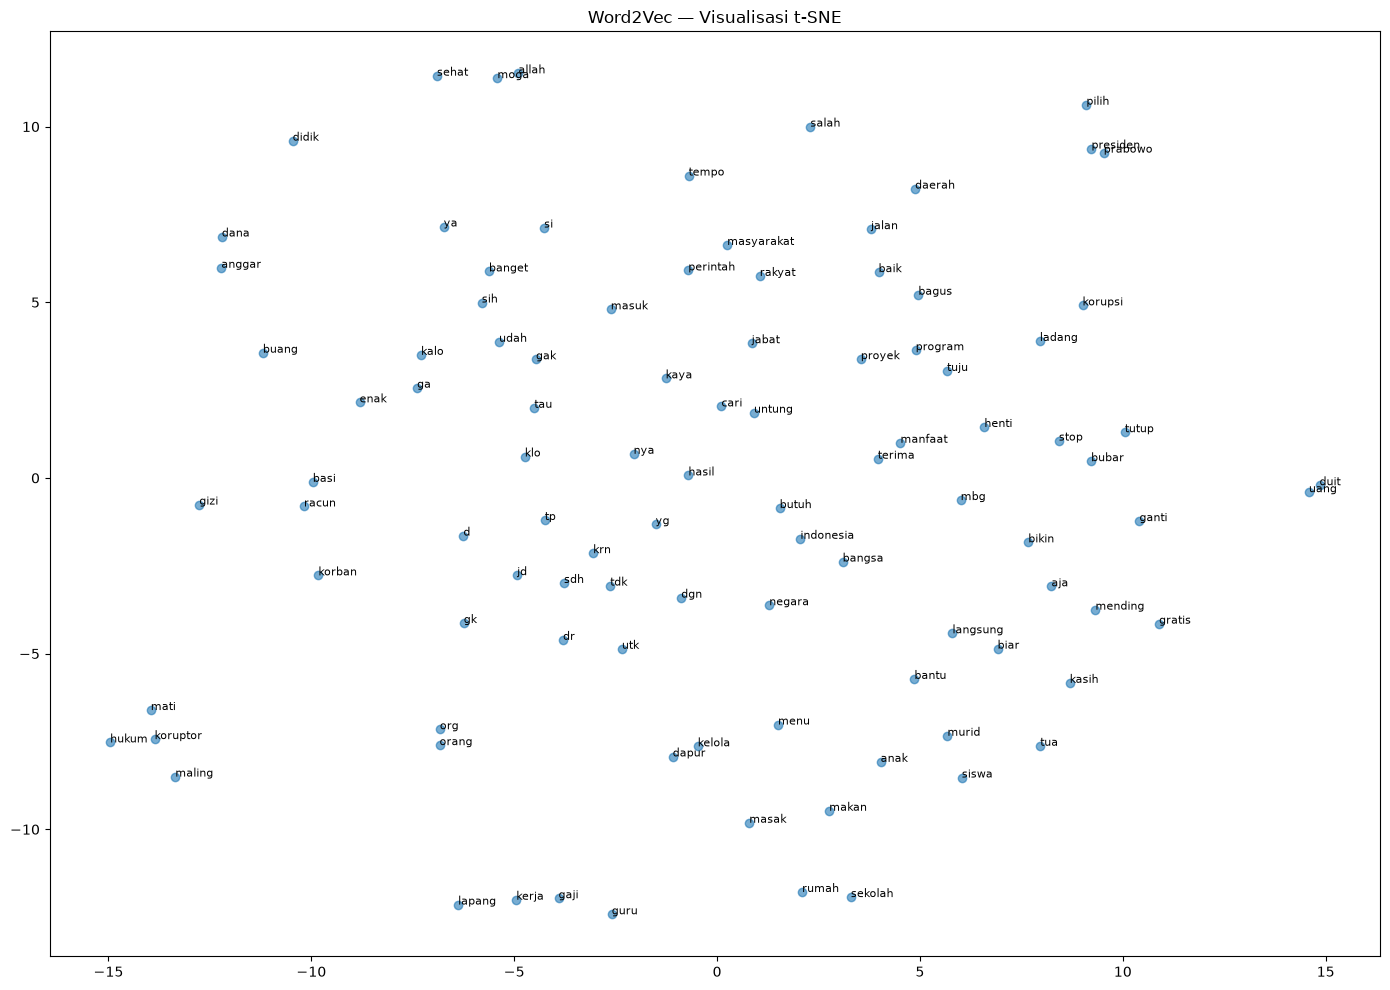

In [16]:
def visualize_embeddings_tsne(words, model, title="Word Embedding t-SNE"):
    valid_words = [w for w in words if w in model.wv]
    if len(valid_words) < 10:
        print("Terlalu sedikit kata untuk t-SNE.")
        return

    vectors = np.array([model.wv[w] for w in valid_words])

    tsne = TSNE(n_components=2, perplexity=15, random_state=42, max_iter=1000)
    vectors_2d = tsne.fit_transform(vectors)

    plt.figure(figsize=(14, 10))
    plt.scatter(vectors_2d[:, 0], vectors_2d[:, 1], alpha=0.6)
    for i, word in enumerate(valid_words):
        plt.annotate(
            word,
            xy=(vectors_2d[i, 0], vectors_2d[i, 1]),
            fontsize=8
        )
    plt.title(title)
    plt.tight_layout()
    plt.show()

top_words = [word for word, _ in model_w2v.wv.key_to_index.items()][:100]
visualize_embeddings_tsne(top_words, model_w2v, "Word2Vec — Visualisasi t-SNE")

In [17]:
# Latih model FastText
model_ft = FastText(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    epochs=10
)

# FastText dapat menangani kata baru (OOV)
oov_word = "ketidakberhasilannya"  # kata yang mungkin tidak ada di corpus
vector_oov = model_ft.wv[oov_word]
print(f"FastText berhasil menghasilkan vektor untuk '{oov_word}'")
print(f"Dimensi: {vector_oov.shape}")

FastText berhasil menghasilkan vektor untuk 'ketidakberhasilannya'
Dimensi: (100,)


In [18]:
test_oov = "pemrogramannya"  # kata dengan imbuhan kompleks

print("Perbandingan Word2Vec vs FastText:")
print("-" * 50)

if test_oov in model_w2v.wv:
    w2v_similar = model_w2v.wv.most_similar(test_oov, topn=5)
    print(f"\nWord2Vec — '{test_oov}':")
    for w, s in w2v_similar:
        print(f"  {w:<20}: {s:.4f}")
else:
    print(f"\nWord2Vec: '{test_oov}' tidak ada dalam vocabulary (OOV)")

ft_similar = model_ft.wv.most_similar(test_oov, topn=5)
print(f"\nFastText — '{test_oov}':")
for w, s in ft_similar:
    print(f"  {w:<20}: {s:.4f}")

Perbandingan Word2Vec vs FastText:
--------------------------------------------------

Word2Vec: 'pemrogramannya' tidak ada dalam vocabulary (OOV)

FastText — 'pemrogramannya':
  prasarana           : 0.9976
  ragu                : 0.9970
  hensa               : 0.9969
  he                  : 0.9969
  hehe                : 0.9965


## Analisis Tugas Pertemuan 7

Jalankan sel berikut untuk membandingkan CBOW dan Skip-gram, menguji relasi kata dan analogi, memvisualisasikan cluster embedding, serta membandingkan Word2Vec dan FastText untuk kata berimbuhan.

In [ ]:
from collections import Counter
from gensim.models import Word2Vec, FastText
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Gunakan teks hasil stemming untuk perbandingan CBOW dan Skip-gram.
analysis_df = pd.read_csv(r"D:\Semester 5\NLP\modul-1\dataset_preprocessed.csv")
analysis_df = analysis_df.dropna(subset=["processed_text", "clean_text"]).reset_index(drop=True)
sentences = [str(text).split() for text in analysis_df["processed_text"]]

model_sg = Word2Vec(
    sentences=sentences, vector_size=100, window=5, min_count=2,
    workers=1, epochs=10, sg=1, seed=42
)
model_cbow = Word2Vec(
    sentences=sentences, vector_size=100, window=5, min_count=2,
    workers=1, epochs=10, sg=0, seed=42
)

# 1. Bandingkan kata-kata terdekat dari model Skip-gram dan CBOW.
print("1. PERBANDINGAN SKIP-GRAM (sg=1) DAN CBOW (sg=0)")
for target in ["bagus", "makan", "anak", "rakyat", "sekolah"]:
    print(f"\nKata: {target}")
    for model_name, model in [("Skip-gram", model_sg), ("CBOW", model_cbow)]:
        if target in model.wv:
            neighbors = model.wv.most_similar(target, topn=5)
            print(f"  {model_name:<10}: {', '.join(f'{word} ({score:.3f})' for word, score in neighbors)}")
        else:
            print(f"  {model_name:<10}: kata tidak ada dalam vocabulary")
print("\nPerhatikan perbedaan daftar dan skor. CBOW sering mengelompokkan konteks umum, "
      "sedangkan Skip-gram belajar dari tiap kata konteks; kualitas hasil juga dipengaruhi corpus.")

# 2. Uji lima pasangan yang secara intuisi berhubungan.
word_pairs = [
    ("bagus", "baik"),
    ("buruk", "jelek"),
    ("makan", "minum"),
    ("anak", "siswa"),
    ("rakyat", "masyarakat"),
]
print("\n2. SIMILARITY LIMA PASANG KATA")
for word_a, word_b in word_pairs:
    print(f"{word_a:<12} - {word_b:<12}", end="")
    for model_name, model in [("Skip-gram", model_sg), ("CBOW", model_cbow)]:
        if word_a in model.wv and word_b in model.wv:
            score = model.wv.similarity(word_a, word_b)
            print(f" | {model_name}: {score:.4f}", end="")
        else:
            print(f" | {model_name}: OOV", end="")
    print()
print("Similarity tinggi menunjukkan kedekatan konteks pada corpus, bukan selalu sinonim.")

# 3. Contoh operasi vektor; hasil aktual ditampilkan sebagai kandidat teratas.
analogy_operations = [
    ("sifat/konteks terkait", ["bagus", "baik"], ["buruk"]),
    ("konteks anak", ["layak", "anak"], ["orang"]),
    ("konteks korupsi", ["korupsi", "uang"], ["rakyat"]),
    ("konteks sekolah", ["sekolah", "guru"], ["rumah"]),
]
print("\n3. OPERASI VEKTOR (positif - negatif)")
for label, positive_words, negative_words in analogy_operations:
    missing = [word for word in positive_words + negative_words if word not in model_sg.wv]
    if missing:
        print(f"{label}: dilewati; kata tidak tersedia: {missing}")
        continue
    results = model_sg.wv.most_similar(
        positive=positive_words, negative=negative_words, topn=3
    )
    expression = " + ".join(positive_words) + " - " + " - ".join(negative_words)
    print(f"{expression} -> {', '.join(f'{word} ({score:.3f})' for word, score in results)}")
print("Interpretasikan kandidat berdasarkan makna dan konteks; analogi pada corpus komentar "
      "yang kecil/noisy tidak selalu menghasilkan relasi sempurna.")

# 4. Cluster K-Means pada 60 kata yang cukup sering; PCA hanya untuk visualisasi 2D.
cluster_words = [
    word for word in model_sg.wv.index_to_key
    if model_sg.wv.get_vecattr(word, "count") >= 10
][:60]
cluster_vectors = np.array([model_sg.wv[word] for word in cluster_words])
cluster_labels = KMeans(n_clusters=4, random_state=42, n_init=10).fit_predict(cluster_vectors)
print("\n4. CLUSTER K-MEANS DAN PCA")
for cluster_id in range(4):
    members = [word for word, label in zip(cluster_words, cluster_labels) if label == cluster_id]
    print(f"Cluster {cluster_id + 1}: {', '.join(members)}")

coordinates = PCA(n_components=2).fit_transform(cluster_vectors)
plt.figure(figsize=(13, 9))
scatter = plt.scatter(
    coordinates[:, 0], coordinates[:, 1], c=cluster_labels,
    cmap="tab10", alpha=0.8
)
for i, word in enumerate(cluster_words):
    plt.annotate(word, (coordinates[i, 0], coordinates[i, 1]), fontsize=8)
plt.title("Cluster Embedding Skip-gram (K-Means) - PCA 2D")
plt.xlabel("Komponen PCA 1")
plt.ylabel("Komponen PCA 2")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()
print("Nama cluster ditafsirkan dari kata-kata anggotanya; jarak PCA adalah proyeksi "
      "2D sehingga tidak sepenuhnya mempertahankan seluruh jarak embedding.")

# 5. Gunakan clean_text (belum di-stem) agar contoh imbuhan asli tetap terlihat.
morph_sentences = [str(text).split() for text in analysis_df["clean_text"]]
model_w2v_morph = Word2Vec(
    sentences=morph_sentences, vector_size=100, window=5, min_count=2,
    workers=1, epochs=10, sg=1, seed=42
)
model_ft_morph = FastText(
    sentences=morph_sentences, vector_size=100, window=5, min_count=2,
    workers=1, epochs=10, sg=1, seed=42, min_n=3, max_n=6
)
morph_pairs = [("makan", "dimakan"), ("main", "bermain"), ("kritik", "dikritik")]
print("\n5. WORD2VEC VS FASTTEXT UNTUK KATA BERIMBUHAN")
for base_word, inflected_word in morph_pairs:
    print(f"\nPasangan: {base_word} / {inflected_word}")
    for model_name, model in [("Word2Vec", model_w2v_morph), ("FastText", model_ft_morph)]:
        if base_word in model.wv.key_to_index and inflected_word in model.wv.key_to_index:
            score = model.wv.similarity(base_word, inflected_word)
            print(f"  {model_name}: keduanya ada di vocabulary; similarity={score:.4f}")
        elif model_name == "FastText":
            score = model.wv.similarity(base_word, inflected_word)
            print(f"  FastText: setidaknya satu bentuk OOV; vektor subword tetap tersedia, similarity={score:.4f}")
        else:
            missing_word = base_word if base_word not in model.wv.key_to_index else inflected_word
            print(f"  Word2Vec: {missing_word} OOV")

oov_inflected_word = "bermainnya"
print(f"\nUji kata OOV: {oov_inflected_word}")
print(f"  Word2Vec punya entri vocabulary: {oov_inflected_word in model_w2v_morph.wv.key_to_index}")
print(f"  FastText punya entri vocabulary: {oov_inflected_word in model_ft_morph.wv.key_to_index}")
if oov_inflected_word in model_ft_morph.wv:
    oov_neighbors = model_ft_morph.wv.most_similar(oov_inflected_word, topn=5)
    print("  Kata terdekat FastText:", ", ".join(
        f"{word} ({score:.3f})" for word, score in oov_neighbors
    ))
print("FastText dapat membentuk vektor OOV dari subword, tetapi itu tidak menjamin "
      "maknanya tepat. Hasil dipengaruhi kualitas corpus; clean_text dipakai karena "
      "processed_text sudah melalui stemming.")